# Adult Income

## Câu 3. Tương quan Pearson

### Yêu cầu

Khảo sát tương quan Pearson, biểu diễn heatmap có giá trị và loại thuộc tính tương quan cao.

### Dữ liệu và phương pháp

Thuộc tính quyết định: income. Sử dụng toàn bộ dữ liệu được cung cấp. Giữ nguyên nguồn train/test sau khi loại dòng trống; nối hai tập để thực hiện quy trình của đề. Tương quan cao được quy ước là |r| ≥ 0,8 giữa các thuộc tính đầu vào; giữ cột đứng trước trong thứ tự gốc.

In [1]:
print("Đặng Ngọc Hiếu - 6451071024")

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "datasets").is_dir():
    if (ROOT / "6451071024_Lab2" / "datasets").is_dir():
        ROOT = ROOT / "6451071024_Lab2"
        break
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Không tìm thấy thư mục datasets của LAB2.")
    ROOT = ROOT.parent
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", font="DejaVu Sans")


train_raw = pd.read_csv(ROOT / "datasets/adult/adult.data.csv", skipinitialspace=True)
test_raw = pd.read_csv(ROOT / "datasets/adult/adult.test.csv", skipinitialspace=True)
if "income" not in train_raw or "income" not in test_raw:
    raise ValueError("Hai tệp Adult phải có cột income.")
if "fnlwgt" not in train_raw or "fnlwgt" in test_raw:
    raise ValueError("Kiểm tra hai phiên bản Adult: fnlwgt chỉ có trong tập huấn luyện.")


Đặng Ngọc Hiếu - 6451071024


In [2]:
print("Đặng Ngọc Hiếu - 6451071024")

# Kiểu string tường minh giúp nhận diện thiếu mà không dựa vào downcasting.
def clean_adult(frame):
    frame = frame.copy()
    for column in frame.select_dtypes(include=["object", "string"]).columns:
        values = frame[column].astype("string").str.strip()
        frame[column] = values.mask(values.isin(["?", ""]))
    return frame.dropna()

train = clean_adult(train_raw).drop(columns="fnlwgt")
test = clean_adult(test_raw)
if list(train.columns) != list(test.columns):
    raise ValueError("Tên và thứ tự cột Adult chưa khớp sau khi bỏ fnlwgt.")
n_train = len(train)
data = pd.concat([train, test], ignore_index=True)
TARGET = "income"


Đặng Ngọc Hiếu - 6451071024


Đặng Ngọc Hiếu - 6451071024
Quy ước tương quan cao: |r| >= 0.8


,age,education-num,capital-gain,capital-loss,hours-per-week
age,1.000000,0.037623,0.079683,0.059351,0.101992
education-num,0.037623,1.000000,0.126907,0.081711,0.146206
capital-gain,0.079683,0.126907,1.000000,-0.032102,0.083880
capital-loss,0.059351,0.081711,-0.032102,1.000000,0.054195
hours-per-week,0.101992,0.146206,0.083880,0.054195,1.000000


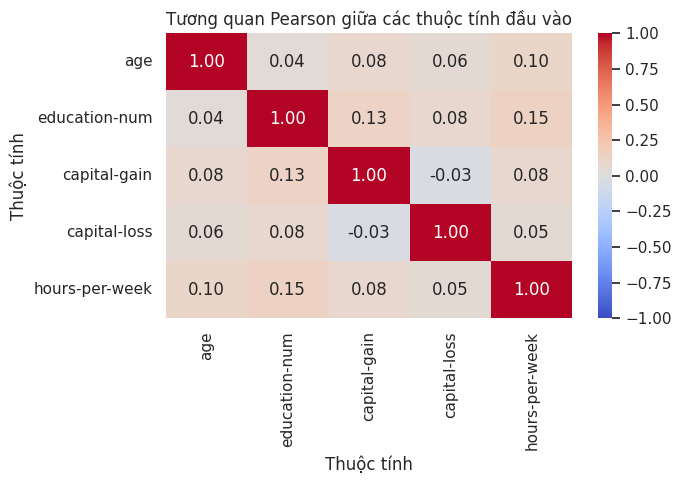

,Cột giữ,Cột loại,Pearson r


Các cột loại: Không có
Kích thước trước loại cột: (45222, 14)
Kích thước sau loại cột: (45222, 14)


In [3]:
print("Đặng Ngọc Hiếu - 6451071024")

# Pearson chỉ có ý nghĩa trực tiếp trên các cột số, không mã hóa nhãn để loại cột.
numeric = data.drop(columns=TARGET).select_dtypes(include="number")
CORRELATION_THRESHOLD = 0.8  # Quy ước triển khai; đề không ấn định ngưỡng số.
corr = numeric.corr(method="pearson")
print("Quy ước tương quan cao: |r| >=", CORRELATION_THRESHOLD)
display(corr)
plt.figure(figsize=(max(7, len(corr)), max(5, len(corr)*0.7)))
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm")
plt.title("Tương quan Pearson giữa các thuộc tính đầu vào")
plt.xlabel("Thuộc tính")
plt.ylabel("Thuộc tính")
plt.tight_layout()
plt.show()
plt.close()

# Xét theo thứ tự cột gốc; giữ cột trước, bỏ cột sau nếu tương quan cao với cột giữ.
drop_columns = []
pairs = []
for j, column in enumerate(corr.columns):
    for previous in corr.columns[:j]:
        value = corr.loc[previous, column]
        if previous not in drop_columns and pd.notna(value) and abs(value) >= CORRELATION_THRESHOLD:
            drop_columns.append(column)
            pairs.append({"Cột giữ": previous, "Cột loại": column, "Pearson r": value})
            break
display(pd.DataFrame(pairs, columns=["Cột giữ", "Cột loại", "Pearson r"]))
print("Các cột loại:", drop_columns if drop_columns else "Không có")
print("Kích thước trước loại cột:", data.shape)
data = data.drop(columns=drop_columns)
print("Kích thước sau loại cột:", data.shape)
